# Viscosity kernels for spherical Stokes flow

This notebook computes the sensitivity of dynamic topography to mantle viscosity
for instantaneous Stokes flow in a spherical shell $c < r < b$, reduced to one
spherical-harmonic degree $l$. It uses `fem_1d.stokes`, which assembles

1. the **forward** weak form, for the flow driven by a buoyancy load, and
2. the **adjoint** weak form, written down directly (not obtained by
   transposing the discrete matrix),

and then combines the two into a kernel $K_\eta(r)$ with
$\delta J = \int_c^b K_\eta\,\delta\eta\,\mathrm dr$.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import fem_1d as fem
from fem_1d import stokes
from fem_1d.plotting import plot_kernel

## 1. Fields and the strain pairing

The unknowns are the radial and tangential velocity $\mathbf u = (U, V)$, the
pressure $P$, and the radial tractions $T_b$ and $T_c$ on the outer and inner
boundaries. With $L = l(l+1)$, the **strain pairing** of two flows
$\mathbf a = (U_a, V_a)$ and $\mathbf b = (U_b, V_b)$ is

$$
\mathcal B(\mathbf a, \mathbf b)
= \dot U_a \dot U_b + \tfrac12 F_a F_b + \tfrac L2 X_a X_b
+ \tfrac{L(L-2)}{2}\frac{V_a V_b}{r^2}
- \tfrac13 (\nabla\!\cdot\!\mathbf a)(\nabla\!\cdot\!\mathbf b),
$$

$$
F = \frac{2U - LV}{r}, \qquad X = \dot V - \frac Vr + \frac Ur, \qquad
\nabla\!\cdot\!\mathbf a = \dot U_a + F_a .
$$

Each of $\dot U$, $F$, $X$, $V/r$ and $\nabla\!\cdot\!\mathbf a$ is a linear
combination of $U$, $V$ and their derivatives. `stokes` multiplies the pairs out
into the package's `Term`s, i.e. integrals of
$c(r)\,\partial^p(\text{trial})\,\partial^q(\text{test})$.

## 2. Forward problem

Find $(\mathbf u, P, T_b, T_c)$ such that, for all test fields
$(\tilde{\mathbf u}, \tilde P, \tilde T_b, \tilde T_c)$,

$$
\begin{aligned}
&\int_c^b 2\eta r^2\,\mathcal B(\mathbf u, \tilde{\mathbf u})\,\mathrm dr
- \int_c^b r^2 P\,\nabla\!\cdot\!\tilde{\mathbf u}\,\mathrm dr
- \int_c^b r^2\,\tilde P \rho_0\Big[\nabla\!\cdot\!\mathbf u + \frac\kappa r U\Big]\mathrm dr \\
&\quad - b^2 T_b\,\tilde U(b) + c^2 T_c\,\tilde U(c)
- b^2 \tilde T_b\,U(b) + c^2 \tilde T_c\,U(c)
= \int_c^b r^2 f\,\tilde U\,\mathrm dr ,
\end{aligned}
$$

with $f$ the radial body force (e.g. $-g\,\delta\rho$). The equations tested by
$\tilde T_b, \tilde T_c$ say $U(b) = U(c) = 0$. These are imposed as Dirichlet
conditions (`stokes.no_flow()`), and the tractions that hold them come back from
the reactions (`stokes.tractions`).

The model: a shell with $c/b = 0.55$, a stiff lower mantle below $r = 0.8$, a
compressible reference density, and a buoyancy anomaly in mid-mantle.

The pressure is **discontinuous**, of degree $n-2$. Normal stress is continuous
across the viscosity jump but is not, and a continuous pressure space
forces Gibbs-like oscillations into the kernel in the element next to the
interface. An element boundary sits on  $r= 0.8$, so the jump falls between
elements.

In [3]:
c, b, l = 0.55, 1.0, 2
r_670 = 0.8  # viscosity jump: put an element boundary on it
eta = lambda r: np.where(r < r_670, 30.0, 1.0)
rho0 = lambda r: np.exp(0.4 * (1 - r))  # reference density
kappa = lambda r: -0.4 * r  # r d(ln rho0)/dr, for the anelastic continuity
f = lambda r: (
    -np.exp(-(((r - 0.75) / 0.05) ** 2))
)  # radial body force: a heavy blob
params = {"eta": eta}

mesh = fem.sized_mesh([c, r_670, b], drmax=0.02)
n = 5
vel = fem.FunctionSpace(mesh, fem.reference_element(n))
pres = fem.FunctionSpace(mesh, fem.reference_element(n - 2), discontinuous=True)
spaces = {"U": vel, "V": vel, "P": pres}

forward = fem.Problem(
    spaces,
    stokes.forward_terms(l, rho0, kappa),
    stokes.body_force(f),
    stokes.no_flow(),
    params,
)
sol = forward.solve()
T_b, T_c = stokes.tractions(sol)
print(f"{forward.n_dofs} dofs;  T_b = {T_b:.4e},  T_c = {T_c:.4e}")

324 dofs;  T_b = 1.0100e-02,  T_c = -1.2367e-01


## 3. Adjoint problem

The observable is a combination of the boundary tractions,
$J = j_{T_b} T_b + j_{T_c} T_c$, for example $j_{T_b} = 1$, $j_{T_c} = 0$ for the
surface traction (dynamic topography up to a factor $1/\Delta\rho g$).

Let $\mathbf u^\dagger = (U^\dagger, V^\dagger)$, $P^\dagger$, $\lambda_b$ and
$\lambda_c$ denote the adjoint velocity, pressure and boundary tractions. The
**adjoint weak form** is: find $(\mathbf u^\dagger, P^\dagger, \lambda_b, \lambda_c)$
such that, for all $(\tilde{\mathbf u}, \tilde P, \tilde T_b, \tilde T_c)$,

$$
\begin{aligned}
&\int_c^b 2\eta r^2\,\mathcal B(\tilde{\mathbf u}, \mathbf u^\dagger)\,\mathrm dr
- \int_c^b r^2\,\tilde P\,\nabla\!\cdot\!\mathbf u^\dagger\,\mathrm dr
- \int_c^b r^2 P^\dagger \rho_0\Big[\nabla\!\cdot\!\tilde{\mathbf u} + \frac\kappa r \tilde U\Big]\mathrm dr \\
&\quad - b^2 \tilde T_b\,U^\dagger(b) + c^2 \tilde T_c\,U^\dagger(c)
- b^2 \lambda_b\,\tilde U(b) + c^2 \lambda_c\,\tilde U(c)
= j_{T_b} \tilde T_b + j_{T_c} \tilde T_c .
\end{aligned}
$$

Choosing the arbitrary fields one at a time separates it into

$$
\begin{aligned}
&\int_c^b 2\eta r^2\,\mathcal B(\tilde{\mathbf u}, \mathbf u^\dagger)\,\mathrm dr
- \int_c^b r^2 P^\dagger \rho_0\Big[\nabla\!\cdot\!\tilde{\mathbf u} + \frac\kappa r \tilde U\Big]\mathrm dr
- b^2 \lambda_b\,\tilde U(b) + c^2 \lambda_c\,\tilde U(c) = 0
&& \text{for all } \tilde{\mathbf u}, \\
&-\int_c^b r^2\,\tilde P\,\nabla\!\cdot\!\mathbf u^\dagger\,\mathrm dr = 0
&& \text{for all } \tilde P, \\
&-b^2\,U^\dagger(b) = j_{T_b}, \qquad +c^2\,U^\dagger(c) = j_{T_c} .
\end{aligned}
$$

The observable enters only through the last line, as Dirichlet values on
$U^\dagger$ (`stokes.adjoint_constraints`). There is no volume load. Note
that the pressure couples differently than in the forward problem: the
anelastic factor $\rho_0[\,\cdot + \kappa U/r]$ now acts on the test velocity.

In [4]:
j_b, j_c = 1.0, 0.0  # J = T_b, the surface traction

adjoint = fem.Problem(
    spaces,
    stokes.adjoint_terms(l, rho0, kappa),
    [],
    stokes.adjoint_constraints(j_b, j_c, b, c),
    params,
)
adj = adjoint.solve()
lam_b, lam_c = stokes.tractions(adj)
print(
    f"U+(b) = {adj.evaluate('U', b)[0]:.4f}  (= -j_b / b^2),   lam_b = {lam_b:.4e},  lam_c = {lam_c:.4e}"
)

U+(b) = -1.0000  (= -j_b / b^2),   lam_b = -4.4631e+01,  lam_c = -1.0023e+02


### Checks

Two quick checks that the directly assembled adjoint is the right one:

- **Transpose.** The adjoint weak form is the forward one with the roles of
  unknown and test field swapped, so its matrix is the transpose of the forward
  matrix. This holds for the matrices as assembled, with no extra
  discretisation error, because both use the same spaces and quadrature.
- **Reciprocity.** Testing the forward problem with the adjoint solution gives
  $J = \int_c^b r^2 f\,U^\dagger\,\mathrm dr$, i.e. $J = \mathbf u^\dagger\cdot\mathbf b$.

In [5]:
print("max |A_adj - A_fwd^T| =", abs(adjoint.A - forward.A.T).max())
print("J = j . T     =", j_b * T_b + j_c * T_c)
print("u+ . b        =", adj.u @ forward.b)

max |A_adj - A_fwd^T| = 1.4551915228366852e-11
J = j . T     = 0.010100234856439757
u+ . b        = 0.0101002348564217


## 4. Fields

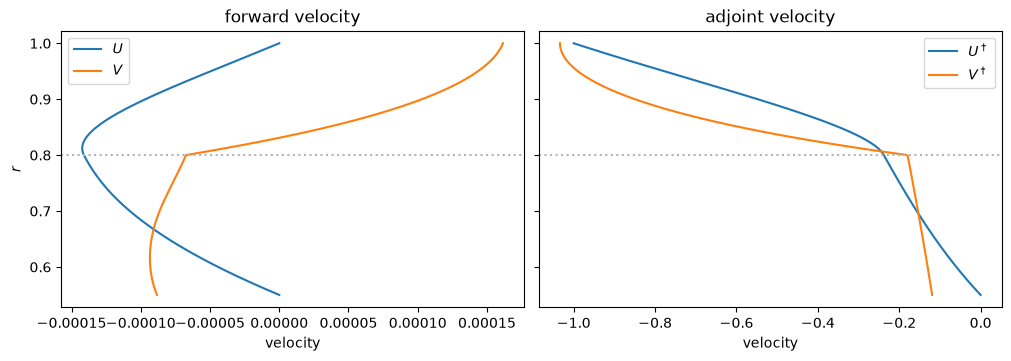

In [6]:
rr = np.linspace(c, b, 400)
fig, axes = plt.subplots(
    1, 2, figsize=(10, 3.5), sharey=True, constrained_layout=True
)
for ax, s, name in [(axes[0], sol, "forward"), (axes[1], adj, "adjoint")]:
    for field in ("U", "V"):
        ax.plot(
            s.evaluate(field, rr),
            rr,
            label=f"${field}$" if name == "forward" else f"${field}^\\dagger$",
        )
    ax.axhline(r_670, color="0.7", ls=":")
    ax.set(title=f"{name} velocity", xlabel="velocity")
    ax.legend()
axes[0].set_ylabel("$r$")
plt.show()

## 5. Viscosity kernel

Perturbing the forward problem and testing with the adjoint solution, only the
viscous term depends on $\eta$, so

$$
\delta J = -\int_c^b 2\,\delta\eta\, r^2\,\mathcal B(\mathbf u, \mathbf u^\dagger)\,\mathrm dr,
\qquad K_\eta(r) = -2 r^2\,\mathcal B(\mathbf u, \mathbf u^\dagger).
$$

`forward.kernel("eta", adjoint=adj)` evaluates this from the terms tagged
`"eta"`, with the adjoint solution in the test slot and the forward solution in
the trial slot. With `relative=True` it gives the kernel for $\delta\ln\eta$,
$K_\eta\,\eta$, which is the usual way to plot viscosity kernels.

In [7]:
K = forward.kernel("eta", adjoint=adj, solution=sol, relative=True)


def J_surface(params):
    return stokes.tractions(
        fem.Problem(
            spaces,
            stokes.forward_terms(l, rho0, kappa),
            stokes.body_force(f),
            stokes.no_flow(),
            params,
        ).solve()
    )[0]


dm = lambda r: np.exp(-(((r - 0.65) / 0.05) ** 2))  # a bump in ln(eta)
eps = 1e-4
fd = (
    J_surface({"eta": lambda r: eta(r) * (1 + eps * dm(r))})
    - J_surface({"eta": lambda r: eta(r) * (1 - eps * dm(r))})
) / (2 * eps)
print(f"kernel: {K.apply(dm):.8e}   finite difference: {fd:.8e}")

kernel: -2.73081470e-03   finite difference: -2.73081469e-03


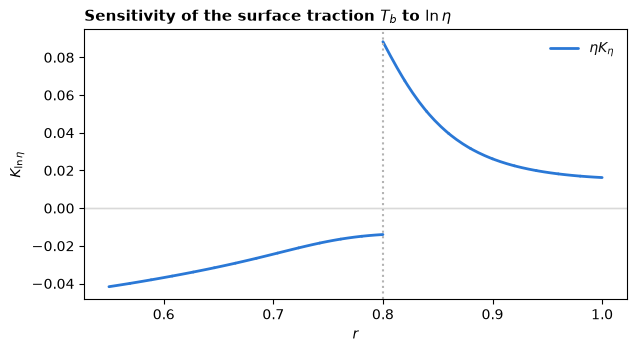

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_kernel(
    K,
    ax=ax,
    label=r"$\eta K_\eta$",
    title=r"Sensitivity of the surface traction $T_b$ to $\ln\eta$",
)
ax.axvline(r_670, color="0.7", ls=":")
ax.axhline(0, color="0.85", lw=1)
ax.set_xlabel("$r$")
plt.show()

## 6. Other observables and degrees

Only the adjoint's Dirichlet values depend on the observable, so the inner
boundary traction ($j_{T_c} = 1$) is one more adjoint solve, with the same
forward solution. Changing the degree $l$ changes both problems.

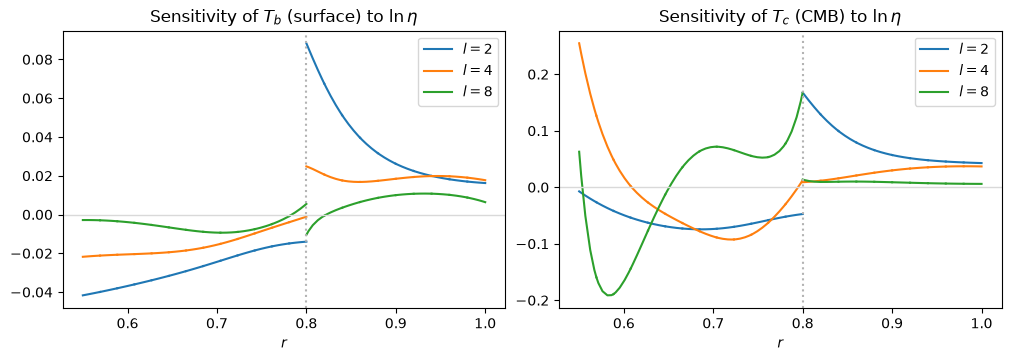

In [9]:
def kernels(l, j_b, j_c):
    fwd = fem.Problem(
        spaces,
        stokes.forward_terms(l, rho0, kappa),
        stokes.body_force(f),
        stokes.no_flow(),
        params,
    )
    adj = fem.Problem(
        spaces,
        stokes.adjoint_terms(l, rho0, kappa),
        [],
        stokes.adjoint_constraints(j_b, j_c, b, c),
        params,
    ).solve()
    return fwd.kernel("eta", adjoint=adj, relative=True)


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, (j_b, j_c, name) in zip(
    axes, [(1.0, 0.0, "$T_b$ (surface)"), (0.0, 1.0, "$T_c$ (CMB)")]
):
    for i, l_ in enumerate((2, 4, 8)):
        Kl = kernels(l_, j_b, j_c)
        for e in range(Kl.x.shape[0]):
            ax.plot(
                Kl.x[e],
                Kl.values[e],
                color=f"C{i}",
                label=f"$l = {l_}$" if e == 0 else None,
            )
    ax.axvline(r_670, color="0.7", ls=":")
    ax.axhline(0, color="0.85", lw=1)
    ax.set(title=f"Sensitivity of {name} to $\\ln\\eta$", xlabel="$r$")
    ax.legend()
plt.show()

## Summary

| Step | Code |
|---|---|
| Forward weak form | `stokes.forward_terms(l, rho0, kappa)`, `stokes.body_force(f)`, `stokes.no_flow()` |
| Adjoint weak form | `stokes.adjoint_terms(l, rho0, kappa)`, `stokes.adjoint_constraints(j_b, j_c, b, c)` |
| Tractions $T_b, T_c$ (or $\lambda_b, \lambda_c$) | `stokes.tractions(solution)` |
| Kernel $K_\eta = -2r^2\mathcal B(\mathbf u, \mathbf u^\dagger)$ | `forward.kernel("eta", adjoint=adj, relative=True)` |